#google drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


#install


edf파일을 읽고 쓰고 조작하는 라이브러리

In [ ]:
!pip install pyedflib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.8/2.8 MB 43.9 MB/s eta 0:00:00


뇌 자기장측정(meg)또는 뇌전도(eeg)데이터를 분석하고 시각화하는 라이브러리

In [ ]:
!pip install mne

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.5/7.5 MB 60.2 MB/s eta 0:00:00


In [ ]:
import pandas as pd
import numpy as np
import tensorflow as tf
import mne

model_path = "/content/drive/MyDrive/sleep-telemetry/sleep_small_model/model_4.keras"
csv_path = "/content/EEG_recording_2026-03-06-04.22.17.csv"
mean_val = np.load("/content/drive/MyDrive/sleep-telemetry/exam_file_dataset_tel/mean.npy")
std_val = np.load("/content/drive/MyDrive/sleep-telemetry/exam_file_dataset_tel/std.npy")

model = tf.keras.models.load_model(model_path)

df = pd.read_csv(csv_path)
raw_data = df[['AF7', 'AF8']].values.T

info = mne.create_info(ch_names=["EEG Fpz-Cz", "EEG Pz-Oz"], sfreq=256, ch_types='eeg')
raw = mne.io.RawArray(raw_data, info)

raw.resample(100)
raw.filter(l_freq=0.5, h_freq=30.0, fir_design='firwin') #

all_data = raw.get_data().T
total_samples = len(all_data)

window_size = 3000
step_size = 100

print(f"{'시간(초)':<10} | {'졸음 상태':<15} | {'졸음 점수 (0-100)':<15}")
print("-" * 50)

for start in range(0, total_samples - window_size, step_size):
    end = start + window_size
    current_window = all_data[start:end] # Shape: (3000, 2)

    # 정규화 및 모델 입력용 차원 확장 (1, 3000, 2)
    test_input = (current_window - mean_val) / std_val
    test_input = test_input[np.newaxis, ...]

    prob = model.predict(test_input, verbose=0)[0]

    # prob[0]: Awake, prob[1]: Stage 1 (졸음), prob[2~]: 수면
    drowsy_score = (prob[1] + prob[2] + prob[3] + prob[4] + prob[5]) * 100
    current_time = (start / 100) + 30 # 예측 기준 시간 (30초 시점부터)

    status = "졸음 위험!" if drowsy_score > 70 else "정상"
    print(f"{current_time:>8.1f}s | {status:<15} | {drowsy_score:>10.2f}")

Creating RawArray with float64 data, n_channels=2, n_times=1296
    Range : 0 ... 1295 =      0.000 ...     5.059 secs
Ready.
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 0.5 - 30 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 0.50
- Lower transition bandwidth: 0.50 Hz (-6 dB cutoff frequency: 0.25 Hz)
- Upper passband edge: 30.00 Hz
- Upper transition bandwidth: 7.50 Hz (-6 dB cutoff frequency: 33.75 Hz)
- Filter length: 661 samples (6.610 s)

시간(초)      | 졸음 상태           | 졸음 점수 (0-100)  
--------------------------------------------------


/tmp/ipykernel_12026/3939895220.py:26: RuntimeWarning: filter_length (661) is longer than the signal (506), distortion is likely. Reduce filter length or filter a longer signal.
  raw.filter(l_freq=0.5, h_freq=30.0, fir_design='firwin') #


#import

In [ ]:
import pyedflib
import numpy as np
from pyedflib import highlevel
from keras.callbacks import EarlyStopping
import matplotlib.pyplot as plt
import pandas as pd
import mne
import os
import glob

#data define

In [ ]:
base_dir = "/content/drive/MyDrive/sleep-telemetry/sleep-edf-database-expanded-1.0.0/sleep-telemetry"

In [ ]:
first_path_list = [
    "011J0","012J0","021J0","022J0","041J0","042J0",
    "051J0","052J0","061J0","062J0","071J0","072J0",
    "081J0","091J0","092J0","101J0","102J0","111J0",
    "112J0","121J0","122J0","131J0","132J0","141J0",
    "142J0","151J0","152J0","161J0","162J0","171J0",
    "172J0","181J0","182J0","191J0","192J0","201J0",
    "202J0","211J0","212J0","221J0"
    ,"222J0","241J0",
    # "242J0"
]

second_path_list = [
    "011JP","012JP","021JM","022JM","041JO","042JO",
    "051JA","052JA","061JR","062JR","071JA","072JA",
    "081JW","091JE","092JE","101JE","102JE","111JE",
    "112JE","121JE","122JE","131JR","132JR","141JE",
    "142JE","151JA","152JA","161JM","162JM","171JA",
    "172JA","181JR","182JR","191JR","192JR","201JO",
    "202JO","211JJ","212JJ","221JA"
    ,"222JA","241JO",
    # "242JO"
]

In [ ]:
psg_paths = [f"{base_dir}/ST7{fp}-PSG.edf" for fp in first_path_list]
hyp_paths = [f"{base_dir}/ST7{sp}-Hypnogram.edf" for sp in second_path_list]

In [ ]:
paired_paths = list(zip(psg_paths, hyp_paths))

In [ ]:
for first, second in paired_paths[:5]:
    print("PSG:", first)
    print("Hypnogram:", second)
    print("---")

PSG: /content/drive/MyDrive/sleep-telemetry/sleep-edf-database-expanded-1.0.0/sleep-telemetry/ST7011J0-PSG.edf
Hypnogram: /content/drive/MyDrive/sleep-telemetry/sleep-edf-database-expanded-1.0.0/sleep-telemetry/ST7011JP-Hypnogram.edf
---
PSG: /content/drive/MyDrive/sleep-telemetry/sleep-edf-database-expanded-1.0.0/sleep-telemetry/ST7012J0-PSG.edf
Hypnogram: /content/drive/MyDrive/sleep-telemetry/sleep-edf-database-expanded-1.0.0/sleep-telemetry/ST7012JP-Hypnogram.edf
---
PSG: /content/drive/MyDrive/sleep-telemetry/sleep-edf-database-expanded-1.0.0/sleep-telemetry/ST7021J0-PSG.edf
Hypnogram: /content/drive/MyDrive/sleep-telemetry/sleep-edf-database-expanded-1.0.0/sleep-telemetry/ST7021JM-Hypnogram.edf
---
PSG: /content/drive/MyDrive/sleep-telemetry/sleep-edf-database-expanded-1.0.0/sleep-telemetry/ST7022J0-PSG.edf
Hypnogram: /content/drive/MyDrive/sleep-telemetry/sleep-edf-database-expanded-1.0.0/sleep-telemetry/ST7022JM-Hypnogram.edf
---
PSG: /content/drive/MyDrive/sleep-telemetry/slee

#data info

In [ ]:
for psg_file in psg_paths[:5]:
    print("="*80)
    print(f"파일 확인: {psg_file}")

    f = pyedflib.EdfReader(psg_file)

    num_signals = f.signals_in_file
    signals = [f.readSignal(i) for i in range(num_signals)]

    header = f.getHeader()
    signal_headers = f.getSignalHeaders()

    num_channels = len(signals)
    print(f"총 채널 수: {num_channels}")

    num_samples = len(signals[0])
    print(f"첫 번째 채널 샘플 수: {num_samples}")

    print("\nEDF 파일 헤더 정보:")
    print(header)

    print("\n각 채널 헤더 정보:")
    for i, h in enumerate(signal_headers):
        num_samples = len(signals[i])
        print(f"채널 {i+1}: {h['label']} | 샘플 수: {num_samples} | 단위: {h['dimension']}")

    f.close()
    print("\n")  # 파일 간 구분

파일 확인: /content/drive/MyDrive/sleep-telemetry/sleep-edf-database-expanded-1.0.0/sleep-telemetry/ST7011J0-PSG.edf
총 채널 수: 5
첫 번째 채널 샘플 수: 3590000

EDF 파일 헤더 정보:
{'technician': '', 'recording_additional': '', 'patientname': '', 'patient_additional': '', 'patientcode': '', 'equipment': '', 'admincode': '', 'sex': '', 'startdate': datetime.datetime(1994, 7, 12, 23, 0), 'birthdate': '', 'gender': ''}

각 채널 헤더 정보:
채널 1: EEG Fpz-Cz | 샘플 수: 3590000 | 단위: uV
채널 2: EEG Pz-Oz | 샘플 수: 3590000 | 단위: uV
채널 3: EOG horizontal | 샘플 수: 3590000 | 단위: uV
채널 4: EMG submental | 샘플 수: 3590000 | 단위: uV
채널 5: Marker | 샘플 수: 359000 | 단위: ID+M-E


파일 확인: /content/drive/MyDrive/sleep-telemetry/sleep-edf-database-expanded-1.0.0/sleep-telemetry/ST7012J0-PSG.edf
총 채널 수: 5
첫 번째 채널 샘플 수: 3132000

EDF 파일 헤더 정보:
{'technician': '', 'recording_additional': '', 'patientname': '', 'patient_additional': '', 'patientcode': '', 'equipment': '', 'admincode': '', 'sex': '', 'startdate': datetime.datetime(1994, 7, 19, 23, 47), 'b

EEG Fpz-Cz (뇌파, 이마–정수리 전극 유도)

EEG Pz-Oz (뇌파, 뒤통수 전극 유도)

EOG horizontal (수평 안구운동 전위)

Resp oro-nasal (구강–비강 호흡 센서)

EMG submental (턱 근전도) : 얼굴 근육에 긴장도 평가용도

Temp rectal (직장 온도) : 체온

Event marker (이벤트 표시기) : 타임라인 체크

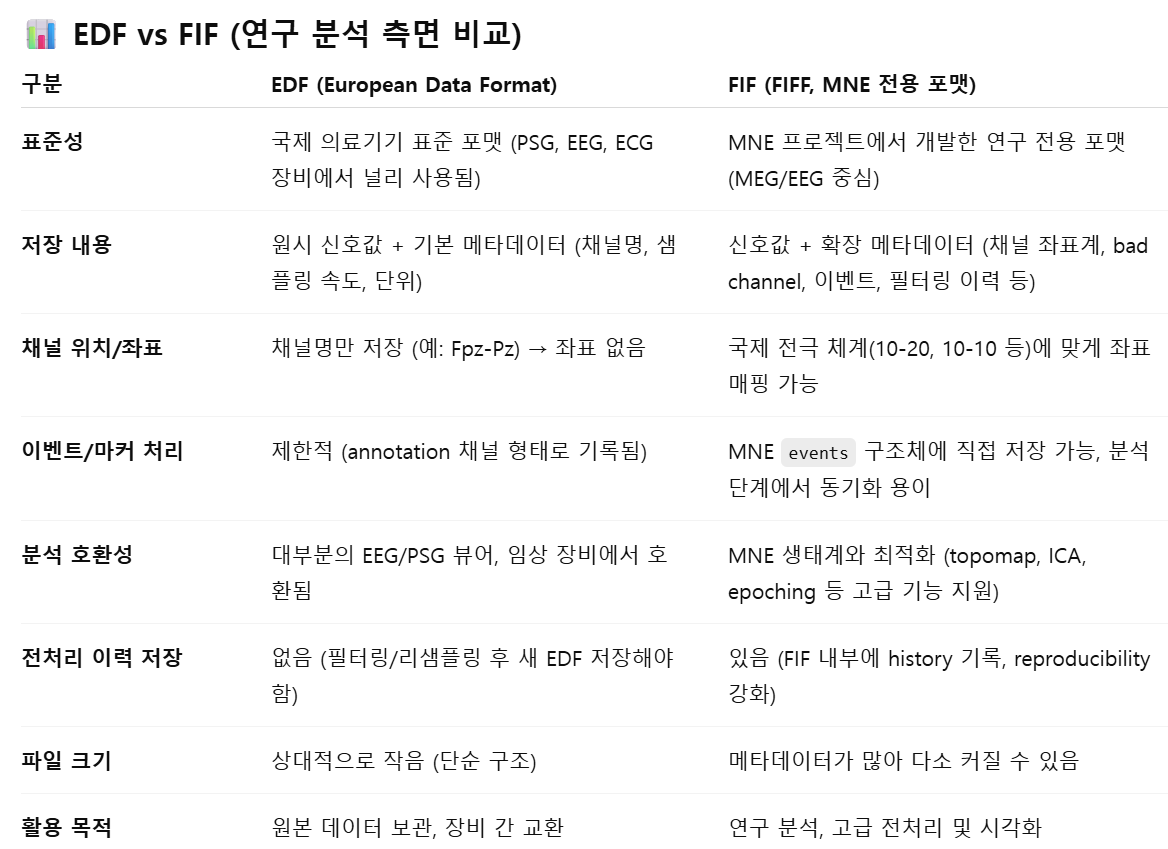

#select brain wave value

In [ ]:
for psg_file, hyp_file in zip(psg_paths, hyp_paths):
    print(f"Processing PSG: {psg_file}")
    print(f"          HYP: {hyp_file}")

    raw = mne.io.read_raw_edf(psg_file, preload=True)

    ann = mne.read_annotations(hyp_file)
    raw.set_annotations(ann)

    raw.pick_channels(["EEG Fpz-Cz", "EEG Pz-Oz"])

    out_file = psg_file.replace(".edf", "-raw.fif").replace(base_dir, "/content/drive/MyDrive/sleep-telemetry/sleep_fif")
    raw.save(out_file, overwrite=True)
    print(f"  Saved: {out_file}")

Processing PSG: /content/drive/MyDrive/sleep-telemetry/sleep-edf-database-expanded-1.0.0/sleep-telemetry/ST7011J0-PSG.edf
          HYP: /content/drive/MyDrive/sleep-telemetry/sleep-edf-database-expanded-1.0.0/sleep-telemetry/ST7011JP-Hypnogram.edf
Extracting EDF parameters from /content/drive/MyDrive/sleep-telemetry/sleep-edf-database-expanded-1.0.0/sleep-telemetry/ST7011J0-PSG.edf...
EDF file detected
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 3589999  =      0.000 ... 35899.990 secs...


/tmp/ipython-input-3456433955.py:5: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw = mne.io.read_raw_edf(psg_file, preload=True)
/tmp/ipython-input-3456433955.py:5: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw = mne.io.read_raw_edf(psg_file, preload=True)


NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
Writing /content/drive/MyDrive/sleep-telemetry/sleep_fif/ST7011J0-PSG-raw.fif
Closing /content/drive/MyDrive/sleep-telemetry/sleep_fif/ST7011J0-PSG-raw.fif
[done]
  Saved: /content/drive/MyDrive/sleep-telemetry/sleep_fif/ST7011J0-PSG-raw.fif
Processing PSG: /content/drive/MyDrive/sleep-telemetry/sleep-edf-database-expanded-1.0.0/sleep-telemetry/ST7012J0-PSG.edf
          HYP: /content/drive/MyDrive/sleep-telemetry/sleep-edf-database-expanded-1.0.0/sleep-telemetry/ST7012JP-Hypnogram.edf
Extracting EDF parameters from /content/drive/MyDrive/sleep-telemetry/sleep-edf-database-expanded-1.0.0/sleep-telemetry/ST7012J0-PSG.edf...
EDF file detected
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 3131999  =      0.000 ... 31319.990 secs...


/tmp/ipython-input-3456433955.py:5: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw = mne.io.read_raw_edf(psg_file, preload=True)
/tmp/ipython-input-3456433955.py:5: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw = mne.io.read_raw_edf(psg_file, preload=True)


NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
Writing /content/drive/MyDrive/sleep-telemetry/sleep_fif/ST7012J0-PSG-raw.fif
Closing /content/drive/MyDrive/sleep-telemetry/sleep_fif/ST7012J0-PSG-raw.fif
[done]
  Saved: /content/drive/MyDrive/sleep-telemetry/sleep_fif/ST7012J0-PSG-raw.fif
Processing PSG: /content/drive/MyDrive/sleep-telemetry/sleep-edf-database-expanded-1.0.0/sleep-telemetry/ST7021J0-PSG.edf
          HYP: /content/drive/MyDrive/sleep-telemetry/sleep-edf-database-expanded-1.0.0/sleep-telemetry/ST7021JM-Hypnogram.edf
Extracting EDF parameters from /content/drive/MyDrive/sleep-telemetry/sleep-edf-database-expanded-1.0.0/sleep-telemetry/ST7021J0-PSG.edf...
EDF file detected
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 3059999  =      0.000 ... 30599.990 secs...


...

NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
Writing /content/drive/MyDrive/sleep-telemetry/sleep_fif/ST7222J0-PSG-raw.fif
Closing /content/drive/MyDrive/sleep-telemetry/sleep_fif/ST7222J0-PSG-raw.fif
[done]
  Saved: /content/drive/MyDrive/sleep-telemetry/sleep_fif/ST7222J0-PSG-raw.fif
Processing PSG: /content/drive/MyDrive/sleep-telemetry/sleep-edf-database-expanded-1.0.0/sleep-telemetry/ST7241J0-PSG.edf
          HYP: /content/drive/MyDrive/sleep-telemetry/sleep-edf-database-expanded-1.0.0/sleep-telemetry/ST7241JO-Hypnogram.edf
Extracting EDF parameters from /content/drive/MyDrive/sleep-telemetry/sleep-edf-database-expanded-1.0.0/sleep-telemetry/ST7241J0-PSG.edf...
EDF file detected
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 3260999  =      0.000 ... 32609.990 secs...


/tmp/ipython-input-3456433955.py:5: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw = mne.io.read_raw_edf(psg_file, preload=True)
/tmp/ipython-input-3456433955.py:5: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw = mne.io.read_raw_edf(psg_file, preload=True)


NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
Writing /content/drive/MyDrive/sleep-telemetry/sleep_fif/ST7241J0-PSG-raw.fif
Closing /content/drive/MyDrive/sleep-telemetry/sleep_fif/ST7241J0-PSG-raw.fif
[done]
  Saved: /content/drive/MyDrive/sleep-telemetry/sleep_fif/ST7241J0-PSG-raw.fif
Processing PSG: /content/drive/MyDrive/sleep-telemetry/sleep-edf-database-expanded-1.0.0/sleep-telemetry/ST7242J0-PSG.edf
          HYP: /content/drive/MyDrive/sleep-telemetry/sleep-edf-database-expanded-1.0.0/sleep-telemetry/ST7242JO-Hypnogram.edf
Extracting EDF parameters from /content/drive/MyDrive/sleep-telemetry/sleep-edf-database-expanded-1.0.0/sleep-telemetry/ST7242J0-PSG.edf...
EDF file detected
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 2947999  =      0.000 ... 29479.990 secs...


/tmp/ipython-input-3456433955.py:5: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw = mne.io.read_raw_edf(psg_file, preload=True)
/tmp/ipython-input-3456433955.py:5: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw = mne.io.read_raw_edf(psg_file, preload=True)


NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
Writing /content/drive/MyDrive/sleep-telemetry/sleep_fif/ST7242J0-PSG-raw.fif
Closing /content/drive/MyDrive/sleep-telemetry/sleep_fif/ST7242J0-PSG-raw.fif
[done]
  Saved: /content/drive/MyDrive/sleep-telemetry/sleep_fif/ST7242J0-PSG-raw.fif


#file exists

In [ ]:
fif_dir = "/content/drive/MyDrive/sleep-telemetry/sleep_tel_fif"
hyp_dir = "/content/drive/MyDrive/sleep-telemetry/sleep-edf-database-expanded-1.0.0/sleep-telemetry"

In [ ]:
psg_files = [os.path.join(fif_dir, f) for f in os.listdir(fif_dir) if f.endswith("-raw.fif")]

hyp_files = [os.path.join(hyp_dir, f"ST7{sp}-Hypnogram.edf") for sp in second_path_list]

for psg, hyp in zip(psg_files, hyp_files):
    print(f"PSG: {psg}, Exists? {os.path.exists(psg)}")
    print(f"HYP: {hyp}, Exists? {os.path.exists(hyp)}")
    print("--------------------------------------------------")


PSG: /content/drive/MyDrive/sleep-telemetry/sleep_tel_fif/ST7011J0-PSG-raw.fif, Exists? True
HYP: /content/drive/MyDrive/sleep-telemetry/sleep-edf-database-expanded-1.0.0/sleep-telemetry/ST7011JP-Hypnogram.edf, Exists? True
--------------------------------------------------
PSG: /content/drive/MyDrive/sleep-telemetry/sleep_tel_fif/ST7012J0-PSG-raw.fif, Exists? True
HYP: /content/drive/MyDrive/sleep-telemetry/sleep-edf-database-expanded-1.0.0/sleep-telemetry/ST7012JP-Hypnogram.edf, Exists? True
--------------------------------------------------
PSG: /content/drive/MyDrive/sleep-telemetry/sleep_tel_fif/ST7021J0-PSG-raw.fif, Exists? True
HYP: /content/drive/MyDrive/sleep-telemetry/sleep-edf-database-expanded-1.0.0/sleep-telemetry/ST7021JM-Hypnogram.edf, Exists? True
--------------------------------------------------
PSG: /content/drive/MyDrive/sleep-telemetry/sleep_tel_fif/ST7022J0-PSG-raw.fif, Exists? True
HYP: /content/drive/MyDrive/sleep-telemetry/sleep-edf-database-expanded-1.0.0/slee

In [ ]:
merge_dir = "/content/drive/MyDrive/sleep-telemetry/merge_dataset_tel"

**npy**로 저장하는 이유는 text기반이 아니라 binary 형식으로 진행한다. 본래는 text로 할때는 csv형태로 진행을 해보았지만 binary 방식은 따로 변환을 하지 않아 속도면에서 압도적이다. 입출력(I/O) 병목 현상이 크게 줄어듬.  그 외에도 continuous 상태로 저장이 됨. 결국 **데이터 누수 방지** 및 **효율성**에 최적화된 파일 형태

In [ ]:
stage_map = {'Sleep stage W': 0,
             'Sleep stage 1': 1,
             'Sleep stage 2': 2,
             'Sleep stage 3': 3,
             'Sleep stage 4': 4,
             'Sleep stage R': 5}

time_step_sec = 30

for psg_file, hyp_file in zip(psg_files, hyp_files):
    file_id = os.path.basename(psg_file).replace("-PSG-raw.fif","")
    print(f"Processing {file_id}")

    raw = mne.io.read_raw_fif(psg_file, preload=True)
    sfreq = raw.info['sfreq']
    n_samples = raw.n_times
    data = raw.get_data().T

    annotations = mne.read_annotations(hyp_file)
    labels = np.zeros(n_samples, dtype=int)
    for desc, onset, duration in zip(annotations.description, annotations.onset, annotations.duration):
        stage = stage_map.get(desc, 0)
        start_sample = int(onset * sfreq)
        end_sample = int((onset + duration) * sfreq)
        end_sample = min(end_sample, n_samples)
        labels[start_sample:end_sample] = stage

    time_step = int(time_step_sec * sfreq)
    X, Y = [], []
    for i in range(0, n_samples - time_step, time_step):
        X.append(data[i:i+time_step])
        Y.append(np.bincount(labels[i:i+time_step]).argmax())
    X = np.array(X)
    Y = np.array(Y)

    np.save(os.path.join(merge_dir, f"X_{file_id}.npy"), X)
    np.save(os.path.join(merge_dir, f"Y_{file_id}.npy"), Y)
    print(f"Saved X_{file_id}.npy and Y_{file_id}.npy")

Processing ST7011J0
Opening raw data file /content/drive/MyDrive/sleep-telemetry/sleep_tel_fif/ST7011J0-PSG-raw.fif...
Isotrak not found
    Range : 0 ... 3589999 =      0.000 ... 35899.990 secs
Ready.
Reading 0 ... 3589999  =      0.000 ... 35899.990 secs...
Saved X_ST7011J0.npy and Y_ST7011J0.npy
Processing ST7012J0
Opening raw data file /content/drive/MyDrive/sleep-telemetry/sleep_tel_fif/ST7012J0-PSG-raw.fif...
Isotrak not found
    Range : 0 ... 3131999 =      0.000 ... 31319.990 secs
Ready.
Reading 0 ... 3131999  =      0.000 ... 31319.990 secs...
Saved X_ST7012J0.npy and Y_ST7012J0.npy
Processing ST7021J0
Opening raw data file /content/drive/MyDrive/sleep-telemetry/sleep_tel_fif/ST7021J0-PSG-raw.fif...
Isotrak not found
    Range : 0 ... 3059999 =      0.000 ... 30599.990 secs
Ready.
Reading 0 ... 3059999  =      0.000 ... 30599.990 secs...
Saved X_ST7021J0.npy and Y_ST7021J0.npy
Processing ST7022J0
Opening raw data file /content/drive/MyDrive/sleep-telemetry/sleep_tel_fif/ST702

## 작업 보고서: 수면 원격 측정 데이터 분석 및 전처리

본 보고서는 수면 원격 측정(sleep telemetry) 데이터 분석 및 전처리를 위해 Colab 환경에서 수행된 일련의 작업을 요약합니다. 목표는 원시 EDF 형식의 수면다원검사(PSG) 데이터와 수면 단계 주석(hypnogram) 데이터를 기계 학습 모델 학습에 적합한 형태로 변환하는 것입니다.

### 1. 환경 설정 및 라이브러리 설치

데이터 접근 및 처리를 위한 기본 환경이 설정되었습니다.

*   **Google Drive 마운트**: `/content/drive` 경로에 Google Drive를 마운트하여 데이터 파일에 접근했습니다. 이는 `google.colab import drive` 및 `drive.mount('/content/drive')` 코드를 통해 이루어졌습니다.
*   **필수 라이브러리 설치**: 수면 데이터 처리에 특화된 두 가지 주요 라이브러리가 설치되었습니다.
    *   `pyedflib`: EDF(European Data Format) 파일을 읽고, 쓰고, 조작하는 데 사용되는 라이브러리입니다. EDF 파일은 EEG, ECG 등 생체 신호 데이터를 저장하는 표준 형식입니다.
    *   `mne`: 뇌 자기장측정(MEG) 또는 뇌전도(EEG) 데이터를 분석하고 시각화하는 데 널리 사용되는 강력한 라이브러리입니다. 복잡한 신호 처리 및 수면 단계 주석 처리에 활용되었습니다.

### 2. 초기 Muse 2 데이터 예측 시연 (사전 모델 활용)

이 섹션은 Muse 2 장치에서 얻은 EEG 데이터와 사전 훈련된 모델을 사용하여 졸음 상태를 예측하는 초기 시연을 보여줍니다. 이는 주된 데이터 전처리 파이프라인과는 별개로, 유사한 유형의 EEG 데이터에 대한 모델 적용 가능성을 탐색한 부분입니다.

*   **사용 모델**: `/content/drive/MyDrive/sleep-telemetry/sleep_small_model/model_4.keras` 경로의 Keras 모델이 로드되었습니다. 이 모델은 특정 EEG 신호를 기반으로 수면 단계를 분류하도록 훈련된 것으로 보입니다.
*   **데이터 로딩 및 전처리**: `/content/EEG_recording_2026-03-06-04.22.17.csv` 파일에서 Muse 2 EEG 데이터(`AF7`, `AF8` 채널)를 로드했습니다. 이 데이터는 `mne.io.RawArray` 객체로 변환되었으며, `EEG Fpz-Cz`, `EEG Pz-Oz` 채널로 매핑되었습니다.
    *   **리샘플링**: 모델의 입력 요구 사항에 맞춰 데이터를 256Hz에서 100Hz로 리샘플링했습니다. 이는 30초 길이의 데이터 창을 3000개 샘플로 유지하기 위함입니다.
    *   **필터링**: 0.5Hz ~ 30Hz 대역통과 필터를 적용하여 EEG 신호에서 관심 주파수 대역만 추출하고 노이즈를 제거했습니다. (`fir_design='firwin'` 사용).
*   **졸음 상태 예측**: 30초 (`window_size = 3000` 샘플) 슬라이딩 윈도우를 1초 (`step_size = 100` 샘플) 단위로 이동하며 데이터를 추출했습니다. 각 윈도우에 대해 정규화(`mean_val`, `std_val` 사용) 후 모델 예측을 수행하고, 예측된 수면 단계 확률을 기반으로 '졸음 점수'를 계산하여 실시간 졸음 상태를 시연했습니다.
    *   **졸음 점수 산정**: `prob[1]` (Stage 1), `prob[2]` (Stage 2), `prob[3]` (Stage 3), `prob[4]` (Stage 4), `prob[5]` (Stage R)의 확률을 합산하여 100을 곱한 값으로 졸음 점수를 정의했습니다. 점수가 70을 초과하면 '졸음 위험!'으로 분류했습니다.
*   **근거**: 이 시연은 실제 수면다원검사 데이터 전처리 전에, 특정 장비(Muse 2)로 획득한 EEG 데이터를 활용하여 학습된 모델의 즉각적인 적용 가능성을 보여주기 위함입니다.

### 3. 수면 원격 측정 데이터 전처리 및 `.fif`, `.npy` 변환

`sleep-edf-database-expanded-1.0.0`에서 제공하는 EDF 형식의 수면다원검사(PSG) 데이터와 Hypnogram 데이터를 기계 학습 모델 학습에 사용하기 위해 전처리 및 효율적인 형식으로 변환하는 과정입니다.

*   **데이터 경로 정의**: `base_dir`을 `/content/drive/MyDrive/sleep-telemetry/sleep-edf-database-expanded-1.0.0/sleep-telemetry`로 설정하고, `first_path_list`와 `second_path_list`에 정의된 고유 식별자를 사용하여 PSG(`-PSG.edf`) 파일과 Hypnogram(`-Hypnogram.edf`) 파일의 전체 경로를 생성했습니다. `paired_paths`를 통해 각 환자별 PSG와 Hypnogram 파일이 올바르게 매칭되었음을 확인했습니다.
*   **EDF 파일 정보 확인**: `pyedflib.EdfReader`를 사용하여 각 PSG 파일의 헤더 정보와 채널별 상세 정보(채널명, 샘플 수, 단위)를 출력하여 데이터 구조를 파악했습니다.
    *   **주요 채널 확인**: `EEG Fpz-Cz`, `EEG Pz-Oz`, `EOG horizontal`, `EMG submental`, `Marker` 등의 채널이 포함되어 있음을 확인했습니다. 이 중 `EEG Fpz-Cz`와 `EEG Pz-Oz`는 뇌파 분석의 핵심 채널입니다.
*   **뇌파 채널 선택 및 `.fif` 변환**: `mne` 라이브러리를 사용하여 EDF 파일을 읽고 특정 뇌파 채널만 선택한 후 MNE의 자체 이진 형식인 `.fif` 파일로 저장했습니다.
    *   `raw = mne.io.read_raw_edf(psg_file, preload=True)`: EDF 파일을 로드합니다.
    *   `ann = mne.read_annotations(hyp_file)` 및 `raw.set_annotations(ann)`: Hypnogram 파일을 읽어 수면 단계 주석을 `raw` 데이터에 적용합니다.
    *   `raw.pick_channels(["EEG Fpz-Cz", "EEG Pz-Oz"])`: 5개의 원본 채널 중 뇌파 분석에 필요한 `EEG Fpz-Cz`와 `EEG Pz-Oz` 두 채널만 선택했습니다. 이는 모델 입력 채널 수를 줄여 계산 효율성을 높이고, 수면 단계 분류에 가장 관련성이 높은 신호에 집중하기 위함입니다.
    *   `raw.save(out_file, overwrite=True)`: 전처리된 데이터를 `/content/drive/MyDrive/sleep-telemetry/sleep_fif` 경로에 `.fif` 형식으로 저장했습니다.
    *   **근거**: `.fif` 형식은 MNE에 최적화된 파일 형식으로, 빠른 데이터 로딩과 효율적인 저장을 가능하게 합니다. 또한, 불필요한 채널을 미리 제거하여 후속 처리 단계를 단순화합니다.
*   **데이터 병합 및 `.npy` 변환 (수면 단계 분류를 위한 에포크 생성)**:
    *   `stage_map` 정의: EDF Hypnogram 파일에 포함된 텍스트 기반 수면 단계 주석(`Sleep stage W`, `Sleep stage 1` 등)을 수치형 레이블(0, 1, 2, 3, 4, 5)로 매핑하는 딕셔너리를 정의했습니다.
    *   `time_step_sec = 30`: 30초를 하나의 수면 에포크(epoch) 단위로 설정했습니다. 이는 수면 단계 분류의 표준 관행입니다.
    *   **데이터 및 레이블 추출**: 각 `.fif` 파일에서 원시 데이터를 로드하고(`mne.io.read_raw_fif`), Hypnogram 파일에서 읽은 주석을 `sfreq` (샘플링 주파수)를 사용하여 각 샘플에 해당하는 수면 단계 레이블(`labels`) 배열로 변환했습니다.
    *   **30초 에포크 생성**: 전체 데이터를 30초 간격으로 슬라이딩하여 `X` (데이터 윈도우)와 `Y` (해당 윈도우의 가장 빈번한 수면 단계 레이블)를 생성했습니다. `np.bincount(labels[i:i+time_step]).argmax()`를 사용하여 30초 내에서 가장 많이 나타나는 수면 단계를 해당 에포크의 대표 레이블로 지정했습니다.
    *   **`.npy` 파일 저장**: 생성된 `X`와 `Y` 데이터를 `/content/drive/MyDrive/sleep-telemetry/merge_dataset_tel` 경로에 NumPy의 바이너리 형식인 `.npy` 파일로 저장했습니다.
    *   **근거**: `.npy` 형식은 텍스트 기반 형식(예: CSV)에 비해 **데이터 누수 방지** 및 **효율성** 측면에서 큰 이점을 가집니다. 바이너리 형식으로 데이터를 연속적으로 저장하여 입출력(I/O) 병목 현상을 줄이고, 데이터 로딩 및 저장 속도를 압도적으로 향상시킵니다. 이는 대용량 시계열 데이터를 처리하고 기계 학습 모델의 입력으로 활용하는 데 매우 적합한 방식입니다. 30초 에포크는 수면 생리학 연구 및 수면 단계 분류 모델에서 표준적으로 사용되는 시간 단위입니다.